# Practical Lab — Local AI with Ollama
**Running and Developing Local AI Applications** · PHD Student 

**Prerequisites:** Python 3.10+, basic Python, basic understanding of APIs, 8–16 GB RAM (NVIDIA GPU optional).

**Technologies:** Ollama · Python · REST API · `requests` · (optional) Open WebUI · a local LLM (Qwen, Gemma, Llama…)

> Ollama exposes a local HTTP service on `localhost:11434`, so the same model can be used from the terminal, Python, or any other software.

### How to use this notebook
- Run cells top to bottom. Cells starting with `!` run shell commands.
- Change `MODEL` / `MODEL2` below if the model names differ on your installation.
- Fill in the **✍️ Your answer** cells — they feed your final report.

## Part 1 — Understanding Local AI

**Cloud AI**
```
Python App → Internet → Cloud API → LLM
```
**Local AI**
```
Python App → localhost:11434 → Ollama → Local LLM → GPU / CPU
```
Advantages to investigate: **privacy**, **offline operation**, **no per-token cost**.
Trade-off: local models may be **less capable or slower** than frontier cloud models, depending on hardware and model size.

## Part 2 — Installing Ollama
### Exercise 1 — Verify the environment

In [1]:
import sys, platform
print("Python  :", sys.version)
print("System  :", platform.system(), platform.release())
assert sys.version_info >= (3, 10), "Python 3.10+ required"

Python  : 3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]
System  : Windows 10


In [2]:
!pip --version

pip 26.2.2 from C:\Users\user\LocalAI_Lab\.venv\Lib\site-packages\pip (python 3.13)



### Exercise 2 — Install Ollama
Download the installer for your OS from <https://ollama.com/download> (Linux: `curl -fsSL https://ollama.com/install.sh | sh`). Then verify:

In [3]:
!ollama --version

ollama version is 0.40.11


Make sure the Ollama service is running (the desktop app starts it automatically; otherwise run `ollama serve` in a separate terminal).

In [4]:
import requests

OLLAMA = "http://localhost:11434"

try:
    r = requests.get(OLLAMA, timeout=3)
    print("✅ Ollama server reachable:", r.text)
except requests.exceptions.ConnectionError:
    print("❌ Ollama is not running. Start it with `ollama serve` in a terminal.")

✅ Ollama server reachable: Ollama is running


## Part 3 — Your First Local LLM
### Exercise 3 — Download a model
If the exact name differs on your installation, pick a small instruct/chat model suited to your hardware.

In [5]:
# Models used throughout the lab — edit if needed
MODEL  = "qwen3.5"   # Model 1
MODEL2 = "gemma3"    # Model 2 (used in the comparison parts)

In [6]:
!ollama pull {MODEL}

pulling manifest â ‹ pulling manifest â ™ pulling manifest â ¹ pulling manifest â ¸ pulling manifest â ¼ pulling manifest â ´ pulling manifest â ¦ pulling manifest â § pulling manifest â ‡ pulling manifest â � pulling manifest â ‹ pulling manifest â ™ pulling manifest â ¹ pulling manifest â ¸ pulling manifest â ¼ pulling manifest â ´ pulling manifest â ¦ pulling manifest â § pulling manifest â ‡ pulling manifest â � pulling manifest â ‹ pulling manifest â ™ pulling manifest â ¹ pulling manifest â ¸ pulling manifest â ¼ pulling manifest â ´ pulling manifest â ¦ pulling manifest â § pulling manifest â ‡ pulling manifest â � pulling manifest â ‹ pulling manifest â ™ pulling manifest 
pulling f836f08f9211:   0% â–•                  â–� 655 KB/921 MB                  pulling manifest 
pulling f836f08f9211:   0% â–•                  â–� 4.1 MB/921 MB                  pulling manifest 
pulling f836f08f9211:   1% â–•                  â–� 6.5 MB/921 MB                  pulling manifest 
pulling

In [7]:
!ollama list

NAME              ID              SIZE      MODIFIED               
qwen3.5:latest    56671c2ab938    6.6 GB    Less than a second ago    
qwen3.5:4b        d8b0f5e9760c    3.3 GB    3 hours ago               


In [10]:
import requests

r = requests.get("http://localhost:11434/api/tags", timeout=10)

print("Status:", r.status_code)
print("Models:", [m["name"] for m in r.json()["models"]])

Status: 200
Models: ['qwen3.5:latest', 'qwen3.5:4b']


In [11]:
import requests
import time

start = time.time()

try:
    response = requests.post(
        "http://localhost:11434/api/generate",
        json={
            "model": "qwen3.5:4b",
            "prompt": "Reply with only the word Hello.",
            "stream": False,
            "think": False,
            "options": {
                "num_predict": 30,
                "num_ctx": 2048
            }
        },
        timeout=600
    )

    response.raise_for_status()

    print("Answer:", response.json()["response"])
    print("Time:", round(time.time() - start, 2), "seconds")

except requests.exceptions.RequestException as e:
    print("Error:", e)

Answer: Hello
Time: 42.81 seconds


In [1]:

import requests
import time

for i in range(3):
    start = time.time()

    response = requests.post(
        "http://localhost:11434/api/generate",
        json={
            "model": "qwen3.5:4b",
            "prompt": "Reply with only Hello.",
            "stream": False,
            "think": False,
            "keep_alive": "10m",
            "options": {
                "num_predict": 30,
                "num_ctx": 2048
            }
        },
        timeout=300
    )

    response.raise_for_status()
    data = response.json()

    print(f"Test {i+1}: {time.time()-start:.2f} seconds")
    print("Answer:", data["response"])
    print("Load time:", round(data.get("load_duration", 0)/1e9, 2), "s")
    print()


Test 1: 25.28 seconds
Answer: Hello
Load time: 22.33 s

Test 2: 2.52 seconds
Answer: Hello
Load time: 0.01 s

Test 3: 2.55 seconds
Answer: Hello
Load time: 0.01 s



### Exercise 4 — Run the model
In the terminal you would use `ollama run qwen3.5`. Here we do the same thing through the API with a helper function.

In [9]:
MODEL = "qwen3.5:4b"
MODEL2 = "gemma3:4b"
OLLAMA = "http://localhost:11434"

print("Selected model:", MODEL)

Selected model: qwen3.5:4b


In [10]:
import time, json

def generate(prompt, model=None, system=None, fmt=None, images=None, options=None, think=None):
    """Call Ollama /api/generate (non-streaming) and return the full JSON dict
    plus the measured wall-clock time under the key 'wall_s'."""
    payload = {"model": model or MODEL, "prompt": prompt, "stream": False}
    if system:  payload["system"] = system
    if fmt:     payload["format"] = fmt          # "json" or a JSON schema
    if images:  payload["images"] = images       # list of base64 strings
    if options: payload["options"] = options
    if think is not None: payload["think"] = think  # False disables 'thinking' on reasoning models
    t0 = time.perf_counter()
    r = requests.post(f"{OLLAMA}/api/generate", json=payload, timeout=600)
    r.raise_for_status()
    out = r.json()
    out["wall_s"] = time.perf_counter() - t0
    return out

def ask(prompt, **kw):
    """Shortcut: return only the text, and print timing."""
    out = generate(prompt, **kw)
    print(f"[{out['wall_s']:.1f}s]")
    return out["response"]

In [11]:
for p in [
    "Explain what artificial intelligence is in five sentences.",
    "Explain artificial intelligence to a 10-year-old child.",
    "Explain artificial intelligence to a computer science professor.",
]:
    print("="*80, "\nPROMPT:", p, "\n")
    print(ask(p))

PROMPT: Explain what artificial intelligence is in five sentences. 

[191.1s]
Artificial intelligence is a branch of computer science dedicated to creating machines capable of simulating human cognitive functions. Unlike traditional software, these intelligent systems can learn from experience and improve their performance over time without being explicitly programmed for every task. They utilize complex algorithms and vast datasets to recognize patterns, make predictions, and solve problems with minimal human intervention. Common applications include voice recognition, autonomous driving, and personalized recommendations based on user behavior. Ultimately, the goal is to augment human capabilities by integrating sophisticated computational power into everyday life.
PROMPT: Explain artificial intelligence to a 10-year-old child. 

[239.9s]
Imagine you have a really smart friend who is amazing at spotting things in pictures or writing poems—but wait, this friend doesn't have a brain! Th

### Questions
1. Did the model produce different answers? Why?
2. Is the model communicating with a cloud API?
3. Where is inference being performed?
4. What happens if the Internet connection is disabled?

> 💡 Try it: disable Wi-Fi / unplug Ethernet and re-run the cell above.

**✍️ Your answer:**

*1. Yes, because the prompts were different. The model adapted its answers to each audience.*
*2. No, it uses the local Ollama API.*
*3. On my computer, mainly using the CPU.*
*4. The model continues working because it runs locally.*

## Part 4 — Experiment with Prompts
### Exercise 5 — Prompt engineering

In [12]:
prompt_a = """You are a university professor.

Explain the concept of a Directed Acyclic Graph (DAG).

Your answer must contain:
1. Definition
2. Example
3. Adjacency matrix
4. Real-world application
5. One Python example"""

print(ask(prompt_a))

[408.9s]
Good afternoon, class. Today we are going to dissect one of the most fundamental data structures in computer science and discrete mathematics: **The Directed Acyclic Graph**, or as we commonly abbreviate it, a **DAG**.

This structure is critical for modeling dependencies where order matters, but loops must be avoided. Let's break this down.

### 1. Definition

To understand a DAG, we must deconstruct two terms used in the name:
*   **Directed:** This implies that the edges (connections between nodes) have direction. Unlike an undirected graph where A is connected to B and B to A are treated equally here, if there is an edge from Node $A$ to Node $B$, you cannot traverse it from $B$ back to $A$.
*   **Acyclic:** This is the constraint that prohibits cycles. A cycle would occur if you could start at a node, follow a path of edges, and return to that same node. If such a path exists, the graph is not acyclic.

**Formal Definition:** A Directed Acyclic Graph (DAG) is a directed g

In [13]:
prompt_b = """You are a university professor.

Explain DAGs to a first-year computer science student.

Use simple language and one concrete example."""

print(ask(prompt_b))

[303.1s]
Hello there! Great question to ask early on. It’s important to understand these concepts because you will encounter them constantly in our courses, software design, and data analysis.

Let’s break down what a **Directed Acyclic Graph (DAG)** is by taking it apart word-by-word, without worrying about complex jargon yet.

### 1. The Basics
Imagine a map or a diagram with points connected to each other. That is a "Graph." In the context of DAGs, we have two specific rules:

*   **Directed:** All the arrows point only one way (like from left to right). If you can go from Point A to Point B, you cannot walk backwards from B to A on that same link.
*   **Acyclic:** This is the most important part. It means **"no loops."** You can follow the path forward forever, but you must never eventually end up back at the starting point. You cannot circle around and come back to where you began.

### 2. The Concrete Example: Your Degree Path
The best way to understand this is to think about **p

### Questions
Compare the two answers. Explain the role of: **role · context · constraints · output format · specificity**.

**✍️ Your answer:**

*Prompt A gives a detailed and technical answer, while Prompt B gives a simpler answer.*
- Role: Tells the AI to act as a professor.
- Context: Defines the topic and audience.
- Constraints: Specify what to include.
- Output format: Organizes the answer.
- Specificity: Makes the answer more precise.

## Part 5 — Model Management
### Exercise 6 — List, show, and monitor models

In [14]:
!ollama list

NAME              ID              SIZE      MODIFIED   
qwen3.5:latest    56671c2ab938    6.6 GB    2 days ago    
qwen3.5:4b        d8b0f5e9760c    3.3 GB    2 days ago    


In [15]:
!ollama show {MODEL}

  Model
    architecture        qwen35             
    parameters          4.2B               
    context length      262144             
    embedding length    2560               
    quantization        Q4_K_M             
    requires            0.30.0             
    renderer            qwen3.5            
    parser              qwen3.5            
    template source     renderer_parser    

  Capabilities
    completion     
    vision         
    tools          
    thinking       
        levels     false, true    
        default    true           

  Projector
    architecture        clip       
    parameters          333.51M    
    embedding length    1024       
    dimensions          2560       

  Parameters
    presence_penalty    1.5     
    temperature         1       
    top_k               20      
    top_p               0.95    

  License
    Apache License               
    Version 2.0, January 2004    
    ...                          



In [16]:
!ollama ps

NAME          ID              SIZE      PROCESSOR         CONTEXT    RUNNER      UNTIL                   
qwen3.5:4b    d8b0f5e9760c    3.2 GB    97%/3% CPU/GPU    4096       llamacpp    About a minute from now    


The same information is available from the REST API (`/api/tags`, `/api/show`, `/api/ps`):

In [17]:
import pandas as pd

def downloaded_models():
    tags = requests.get(f"{OLLAMA}/api/tags").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "family": m["details"].get("family"),
        "params": m["details"].get("parameter_size"),
        "quantization": m["details"].get("quantization_level"),
    } for m in tags])

def loaded_models():
    ps = requests.get(f"{OLLAMA}/api/ps").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "in_VRAM_GB": round(m.get("size_vram", 0)/1e9, 2),
        "expires_at": m.get("expires_at"),
    } for m in ps])

print("Downloaded:"); display(downloaded_models())
print("Currently loaded in memory:"); display(loaded_models())

Downloaded:


,name,size_GB,family,params,quantization
0,qwen3.5:latest,6.55,qwen35,9.0B,Q4_K_M
1,qwen3.5:4b,3.32,qwen35,4.2B,Q4_K_M


Currently loaded in memory:


,name,size_GB,in_VRAM_GB,expires_at
0,qwen3.5:4b,3.2,0.1,2026-10-27T14:36:16.2175533+01:00


### Questions
- What information do you get from `ollama list` vs `ollama ps`?
- What is the difference between a model that is **downloaded** and one that is **loaded**?

**✍️ Your answer:**

*ollama list shows all downloaded models. ollama ps shows models currently loaded in memory.*
*A downloaded model is stored on the computer. A loaded model is in memory and ready to run.*

## Part 6 — Compare Two Local Models
Install a second model suited to your computer.

In [18]:
!ollama pull {MODEL2}
!ollama list

pulling manifest â ‹ pulling manifest â ™ pulling manifest â ¹ pulling manifest â ¸ pulling manifest â ¼ pulling manifest â ´ pulling manifest â ¦ pulling manifest â § pulling manifest â ‡ pulling manifest â � pulling manifest â ‹ pulling manifest â ™ pulling manifest â ¹ pulling manifest â ¸ pulling manifest â ¼ pulling manifest â ´ pulling manifest â ¦ pulling manifest â § pulling manifest â ‡ pulling manifest â � pulling manifest 
pulling f06e91e18fc7:   0% â–•                  â–� 914 KB/2.5 GB                  pulling manifest 
pulling f06e91e18fc7:   0% â–•                  â–� 2.2 MB/2.5 GB                  pulling manifest 
pulling f06e91e18fc7:   0% â–•                  â–� 2.5 MB/2.5 GB                  pulling manifest 
pulling f06e91e18fc7:   0% â–•                  â–� 3.6 MB/2.5 GB                  pulling manifest 
pulling f06e91e18fc7:   0% â–•                  â–� 5.1 MB/2.5 GB                  pulling manifest 
pulling f06e91e18fc7:   0% â–•                  â–� 5.6 M

NAME              ID              SIZE      MODIFIED               
gemma3:4b         68ceab7e468a    3.4 GB    Less than a second ago    
qwen3.5:latest    56671c2ab938    6.6 GB    2 days ago                
qwen3.5:4b        d8b0f5e9760c    3.3 GB    2 days ago                


### Exercise 7 — Same prompt, different models

In [19]:
prime_prompt = """Write a Python function that determines whether a number is prime.

Requirements:
- Python
- Type hints
- Docstring
- Explain the algorithm
- Give its time complexity"""

results = {}
for m in (MODEL, MODEL2):
    print("="*80, f"\nMODEL: {m}\n")
    out = generate(prime_prompt, model=m)
    results[m] = out
    print(out["response"])
    print(f"\n⏱ {out['wall_s']:.1f}s")

MODEL: qwen3.5:4b

# Prime Number Checker in Python

Here's a well-documented, efficient Python function to determine whether a number is prime, using optimized trial division. It includes type hints, docstrings, example usage, and a detailed explanation of the algorithm and its time complexity.

## Code Implementation

```python
def is_prime(number: int) -> bool:
    """
    Determine whether a given integer is a prime number.

    A prime number is a natural number greater than 1 that has no positive 
    divisors other than 1 and itself.

    Args:
        number (int): The integer to check for primality.

    Returns:
        bool: True if the number is prime, False otherwise.

    Raises:
        TypeError: If input is not an integer.
        ValueError: If number is less than 2.
    """
    # Basic input validation
    if not isinstance(number, int):
        raise TypeError("Input must be an integer.")
    if number < 2:
        raise ValueError("Number must be greater than or eq

Now fill in your evaluation (scores out of 5) and see the table:

In [20]:
scores = {
    MODEL:  {"Response quality /5": None, "Code correctness /5": None},
    MODEL2: {"Response quality /5": None, "Code correctness /5": None},
}  # <- replace None with your scores

table = pd.DataFrame([
    {"Model": m, "Response time (s)": round(results[m]["wall_s"], 1), **scores[m]}
    for m in (MODEL, MODEL2)
])
table

,Model,Response time (s),Response quality /5,Code correctness /5
0,qwen3.5:4b,178.0,None,None
1,gemma3:4b,122.0,None,None


**Tip — test the generated code:** copy the function the model wrote into a cell and check it.

In [23]:
def is_prime_reference(n: int) -> bool:
    if n < 2: return False
    if n < 4: return True
    if n % 2 == 0: return False
    i = 3
    while i * i <= n:
        if n % i == 0: return False
        i += 2
    return True

def is_prime(number: int) -> bool:
    if number <= 1:
        return False

    if number <= 3:
        return True

    if number % 2 == 0 or number % 3 == 0:
        return False

    i = 5
    while i * i <= number:
        if number % i == 0 or number % (i + 2) == 0:
            return False
        i += 6

    return True
# Paste the model's function below as `candidate` and compare:
candidate = is_prime
assert all(candidate(n) == is_prime_reference(n) for n in range(-5, 2000)), "Incorrect!"
print("✅ candidate matches the reference on 0..2000")

✅ candidate matches the reference on 0..2000


### Questions
Which model is faster? Which produces better code? Which uses more memory? Which would you choose for programming assistance? Is the largest model necessarily the best?

**✍️ Your answer:**

*Which model is faster? Gemma 3 is faster (122 s vs 178 s).
Which produces better code? Gemma 3 produces better code and handles edge cases correctly.
Which uses more memory? We cannot tell without measuring memory usage for both models.
Which would you choose for programming assistance? Gemma 3, because it is faster and produces better code in this test.
Is the largest model necessarily the best? No, smaller models can sometimes perform better.*

## Part 7 — Using Local AI from Python
### Exercise 8 — Python + Ollama
Project structure:
```
local_ai_lab/
├── app.py
├── requirements.txt
└── README.md
```
Install `requests` (already available here):

In [24]:
!pip install -q requests

In [25]:
import os
os.makedirs("local_ai_lab", exist_ok=True)

In [27]:
%%writefile local_ai_lab/app.py
import requests

url = "http://localhost:11434/api/generate"

data = {
    "model": "qwen3.5:4b",
    "prompt": "Explain recursion in Python.",
    "stream": False
}

response = requests.post(url, json=data)
result = response.json()
print(result["response"])

Overwriting local_ai_lab/app.py


In [28]:
%%writefile local_ai_lab/requirements.txt
requests

Writing local_ai_lab/requirements.txt


In [29]:
%%writefile local_ai_lab/README.md
# local_ai_lab
Minimal Python client for a local Ollama server.
Run: `python app.py`

Writing local_ai_lab/README.md


In [30]:
!python local_ai_lab/app.py

Recursion is a fundamental concept in computer science and programming where a function **calls itself** to solve a problem. It breaks a complex problem into smaller, identical sub-problems until a simple case (the base case) is reached.

Here is a comprehensive guide on how recursion works in Python.

---

### 1. The Core Concept
To write recursion correctly, you need two essential components:
1.  **The Base Case (Stop Condition):** This is the condition that stops the recursion. If this isn't met, the function will call itself forever, leading to a crash.
2.  **The Recursive Step:** This is where the function calls itself with modified input (usually getting it closer to the base case).

### 2. Classic Example: Factorial Calculation
The factorial of a number $n$ (written as $n!$) is the product of all positive integers less than or equal to $n$.
Formula: $5! = 5 \times 4 \times 3 \times 2 \times 1 = 120$

**Recursive Definition:**
*   Base Case: If $n = 1$, return 1.
*   Recursive St

**Architecture:** `Python → HTTP POST → localhost:11434 → Ollama → Local LLM → response → Python`

Below is the same call shown step by step, including the **metadata** Ollama returns:

In [31]:
out = generate("Explain recursion in Python.")
print(out["response"][:600], "...\n")
print({k: v for k, v in out.items() if k not in ("response", "context", "thinking")})

Recursion is a programming technique where a function calls itself to solve smaller versions of the same problem. In Python, recursion enables elegant solutions for tasks such as traversing data structures, solving algorithms like binary search or factorial calculation, and more—though it must be used carefully due to potential performance or memory limitations.

---

### How Recursion Works

Every recursive function in Python consists of two parts:

1. **Base Case (Termination Condition):** This stops the recursion from continuing indefinitely by returning a value when certain conditions are  ...

{'model': 'qwen3.5:4b', 'created_at': '2026-10-27T16:10:01.0249662Z', 'done': True, 'done_reason': 'stop', 'total_duration': 159946046100, 'load_duration': 5038100, 'prompt_eval_count': 16, 'prompt_eval_cached_count': 12, 'prompt_eval_duration': 300965000, 'eval_count': 1117, 'eval_duration': 159589044000, 'wall_s': 162.01092530001188}


## Part 8 — Build a Local AI Chatbot
### Exercise 9 — Interactive chatbot
`input()` works inside Jupyter (a prompt box appears). Type `exit` to stop.

In [32]:
URL = f"{OLLAMA}/api/generate"

def ask_ai(prompt):
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    return response.json()["response"]

def chat_loop_stateless():
    print("Local AI Assistant\nType 'exit' to stop.")
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai(question))

chat_loop_stateless()   # <- uncomment to run

Local AI Assistant
Type 'exit' to stop.



You:  What is Python?



AI: **Python** is a high-level, interpreted, general-purpose programming language known for its simplicity, readability, and versatility. It has become one of the most popular languages in the world for a variety of tasks, from simple scripts to complex data science projects.

Here is a breakdown of what makes Python significant:

### 1. Key Characteristics
*   **Readability:** The code is written in an English-like syntax using indentation rather than braces or semicolons. This makes it very easy for beginners to read and write.
*   **Interpreted:** Unlike compiled languages (like C++ or Java), Python code is executed line-by-line by an interpreter at runtime, which makes debugging easier.
*   **Dynamically Typed:** Variable types don't need to be declared beforehand; the interpreter determines them automatically.
*   **Extensive Libraries:** Because of the large and active community, there are thousands of free modules available for almost any task (e.g., `pip` package manager).
*  


You:  exit


In [33]:
# Non-interactive test (works without typing):
for q in ["What is machine learning?", "Explain reinforcement learning."]:
    print("You:", q); print("AI:", ask_ai(q)[:500], "...\n")

You: What is machine learning?
AI: **Machine Learning (ML)** is a subset of **Artificial Intelligence (AI)**. In simple terms, it is the science of giving computers the ability to learn from data and improve their performance over time **without being explicitly programmed for every specific task.**

Instead of coding complex instructions like "if this button is pressed, then do this," machine learning algorithms analyze patterns in data to make decisions or predictions.

Here is a breakdown of what that actually means:

### 1. H ...

You: Explain reinforcement learning.
AI: Reinforcement Learning (RL) is a type of machine learning where an intelligent system, called an **agent**, learns to make decisions by interacting with a dynamic environment to maximize a cumulative reward.

Unlike other types of AI that might be told what to do directly, RL agents learn through **trial and error**.

Here is a breakdown of how Reinforcement Learning works, its key components, and why it matters.



## Part 9 — Add Conversation Memory
The previous app treats each question independently. We now send the **conversation history** with each request.

In [34]:
history = []

def ask_ai_memory(question):
    history.append(f"User: {question}")
    prompt = "\n".join(history) + "\nAssistant:"
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    answer = response.json()["response"]
    history.append(f"Assistant: {answer}")
    return answer

def chat_loop_memory():
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai_memory(question))

chat_loop_memory()   # <- uncomment for interactive use


You:   My name is tawfik



AI: Hello Tawfik! It's nice to meet you. How can I assist you today?



You:   What is my name?



AI: Your name is Tawfik.



You:  exit


In [35]:
history.clear()
for q in ["My name is Ahmed.", "What is my name?"]:
    print("You:", q)
    print("AI :", ask_ai_memory(q), "\n")

You: My name is Ahmed.
AI : Nice to meet you, Ahmed! How can I help you today? 

You: What is my name?
AI : That is right, your name is Ahmed! 



In [36]:
print("What the model actually received on the last call:\n" + "-"*50)
print("\n".join(history[:-1]) + "\nAssistant:")

What the model actually received on the last call:
--------------------------------------------------
User: My name is Ahmed.
Assistant: Nice to meet you, Ahmed! How can I help you today?
User: What is my name?
Assistant:


### Question
Why does the model remember the name? Is the LLM itself remembering?

**✍️ Your answer:**

*(Hint: look at the printed prompt above. Is anything stored inside the model between calls?)*
The model remembers the name because Python stores the conversation history and sends it again with each new request. The LLM itself does not remember previous calls. 

---
#### Better approach: the `/api/chat` endpoint
Ollama also has a chat endpoint taking structured `messages` (with `system` / `user` / `assistant` roles) and applying the model's own chat template.

In [37]:
def chat(messages, model=None, **kw):
    payload = {"model": model or MODEL, "messages": messages, "stream": False, **kw}
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()

msgs = [{"role": "system", "content": "You are a concise assistant."},
        {"role": "user", "content": "My name is Ahmed."}]
reply = chat(msgs)["message"]
msgs.append(reply)
msgs.append({"role": "user", "content": "What is my name?"})
print(chat(msgs)["message"]["content"])

Your name is Ahmed.


## Part 10 — Local AI for Software Engineering
### Exercise 10 — Code assistant

In [39]:
java_review = """You are a senior Java developer.

Review the following Java code:

public class Calculator {

    public int divide(int a, int b) {
        return a / b;
    }
}

Identify:
1. Potential problems
2. Runtime errors
3. Improvements
4. Corrected code"""

print(ask(java_review))

[516.1s]
As a Senior Java Developer, I will review this code with a focus on robustness, maintainability, adherence to Java best practices, and exception handling strategies.

### 1. Potential Problems
*   **Missing Input Validation:** There is no check to ensure that the denominator (`b`) is valid. If `b` is zero, the method crashes the application.
*   **Lack of Documentation:** The class has no Javadoc explaining what the method does, its parameters, or its exceptions. This hurts discoverability and API clarity.
*   **Primitive vs. Wrapper Type Confusion:** While primitives are generally preferred for performance in math operations (to avoid autoboxing), there is no indication if `b` could theoretically be null if this were a factory pattern (though currently it is `int`).
*   **No Error Handling Strategy:** The method relies entirely on the underlying JVM behavior. If the caller doesn't handle `ArithmeticException`, the stack trace will be messy and unprofessional.

### 2. Runtime 

In [40]:
buggy = """You are a senior Java developer.

Find the bug in this code and explain how to fix it:

public class Student {

    private String name;
    private int age;

    public Student(String name) {
        this.name = name;
    }

    public void setAge(int age) {
        age = age;
    }

    public String getName() {
        return name;
    }
}"""

print(ask(buggy))

[125.3s]
## Bug Found: SetAge Method Does Nothing Actual Updates the Age Field

### 🐛 Root Cause

The bug lies in the `setAge` method:

```java
public void setAge(int age) {
    age = age;  // ❌ This does nothing
}
```

Here, the parameter `age` is reassigned to itself without modifying the instance variable `this.age`. As a result, changes through this setter have no effect on the object's state.

### ✅ How to Fix It

Update the `setAge` method to correctly assign the parameter value to the object's field:

```java
public void setAge(int age) {
    this.age = age;  // ✅ Now it will properly update the instance variable
}
```

### 🔍 Demonstration of the Bug

Without the fix, you might expect this behavior, but in practice, it doesn't work:

```java
Student s1 = new Student("Alice");
s1.setAge(20);
System.out.println(s1.getName()); // "Alice" ✓
System.out.println(s1.getAge());  // Null or 0? Age field was never set (Bug)

Student s2 = new Student("Bob");
s2.setAge(25);
s1.setAge(s2.getA

> ✅ Expected finding: `age = age;` assigns the parameter to itself (variable shadowing); it should be `this.age = age;`. Did your model find it? Is `age` also never initialized in the constructor?
> Yes, the model found the bug and corrected it using this.age = age;. The age field is not initialized in the constructor, but Java automatically sets it to 0

## Part 11 — Structured Output
### Exercise 11
First, the naive approach: ask for "ONLY JSON" in the prompt.

In [41]:
json_prompt = """Analyze the following student:

Name: Ahmed
Age: 21
Grade: 15.5
Absences: 2

Return ONLY JSON with this structure:

{
  "name": "...",
  "age": 0,
  "grade": 0,
  "risk": "...",
  "recommendation": "..."
}"""

raw = ask(json_prompt, think=False)
print(raw)

[40.7s]
{
  "name": "Ahmed",
  "age": 21,
  "grade": 15.5,
  "risk": "low",
  "recommendation": "Continue current trajectory; minimal intervention needed due to strong academic performance and limited absences."
}


In [42]:
import re

def extract_json(text):
    """Robust parsing: strip ```json fences and grab the first {...} block."""
    text = re.sub(r"```(?:json)?", "", text).strip()
    m = re.search(r"\{.*\}", text, re.DOTALL)
    return json.loads(m.group(0))

try:
    print(extract_json(raw))
except Exception as e:
    print("❌ Could not parse:", e)

{'name': 'Ahmed', 'age': 21, 'grade': 15.5, 'risk': 'low', 'recommendation': 'Continue current trajectory; minimal intervention needed due to strong academic performance and limited absences.'}


Better: use Ollama's **structured outputs** — pass a JSON Schema in `format` so the output is constrained to be valid.

In [43]:
schema = {
    "type": "object",
    "properties": {
        "name": {"type": "string"},
        "age": {"type": "integer"},
        "grade": {"type": "number"},
        "risk": {"type": "string", "enum": ["low", "medium", "high"]},
        "recommendation": {"type": "string"},
    },
    "required": ["name", "age", "grade", "risk", "recommendation"],
}

out = generate(json_prompt, fmt=schema, think=False)
student = json.loads(out["response"])
print(json.dumps(student, indent=2))
print("Type of grade:", type(student["grade"]))

{
  "name": "Ahmed",
  "age": 21,
  "grade": 15.5,
  "risk": "medium",
  "recommendation": "Monitor academic performance due to recent absences; encourage attendance and seek support if needed."
}
Type of grade: <class 'float'>


### Question
Why is structured output important when integrating an LLM into a software application?

**✍️ Your answer:**

*Structured output ensures consistent and valid data that software applications can easily process and use.*

## Part 12 — Local AI Document Assistant
Create `documents/course.txt`:

In [44]:
os.makedirs("documents", exist_ok=True)
with open("documents/course.txt", "w", encoding="utf-8") as f:
    f.write("""Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.
""")

### Exercise 12 — Read the document and ask questions

In [45]:
with open("documents/course.txt", "r", encoding="utf-8") as file:
    document = file.read()
print(document)

Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.



In [46]:
def ask_document(question, document):
    prompt = f"""
Answer the question using only the following document.

DOCUMENT:
{document}

QUESTION:
{question}

If the answer is not contained in the document,
say: "Information not available."
"""
    return ask(prompt, think=False)

print(ask_document("What is reinforcement learning?", document))
print()
print(ask_document("What is quantum computing?", document))

[30.9s]
Reinforcement learning learns through interaction with an environment using rewards and penalties.

[4.3s]
Information not available.


**Observe:** the second answer should be *"Information not available."* — the model is grounded in the supplied document instead of its own training data. Does your model respect the instruction every time?

**✍️ Your observation:**

*Yes, the model respected the instructions. It answered using the document and returned "Information not available" when the answer was not found.*

## Part 13 — Mini-RAG
We create four documents, then build a **local retriever** that picks the most relevant one for a question and feeds it to the LLM.

In [47]:
docs = {
"ai.txt": """Artificial intelligence (AI) is the field of computer science that builds systems able to perform tasks normally requiring human intelligence, such as reasoning, perception, language understanding and decision making. AI includes machine learning, expert systems, robotics and natural language processing.""",

"machine_learning.txt": """Machine learning is a branch of artificial intelligence. Supervised learning uses labelled data to learn a mapping from inputs to outputs (classification, regression). Unsupervised learning works with unlabelled data to discover structure such as clusters. Overfitting happens when a model memorises training data and generalises poorly.""",

"reinforcement_learning.txt": """Reinforcement learning learns through interaction with an environment using rewards and penalties. An agent observes a state, chooses an action, and receives a reward. The goal is to learn a policy that maximises the cumulative reward. Q-learning and policy gradients are common algorithms.""",

"deep_learning.txt": """Deep learning uses artificial neural networks with many layers to learn representations from large amounts of data. Convolutional neural networks are used for images, recurrent networks and transformers for sequences and language. Training deep networks usually requires GPUs.""",
}

for name, text in docs.items():
    with open(f"documents/{name}", "w", encoding="utf-8") as f:
        f.write(text)
os.listdir("documents")

['ai.txt',
 'course.txt',
 'deep_learning.txt',
 'machine_learning.txt',
 'reinforcement_learning.txt']

In [48]:
%%writefile rag.py
"""Mini-RAG: a tiny local retriever + prompt builder (keyword TF-IDF, no extra libraries)."""
import math, os, re
from collections import Counter

STOPWORDS = set("""a an the of to in on and or is are was were be by for with as at from that this
it its what which who how why when where do does did can could should would about into using use
learn learns through between such""".split())


def tokenize(text):
    return [w for w in re.findall(r"[a-zA-Z]+", text.lower()) if w not in STOPWORDS]


def load_documents(folder="documents"):
    docs = {}
    for fn in sorted(os.listdir(folder)):
        if fn.endswith(".txt"):
            with open(os.path.join(folder, fn), encoding="utf-8") as f:
                docs[fn] = f.read()
    return docs


class Retriever:
    def __init__(self, docs):
        self.docs = docs
        self.tokens = {n: Counter(tokenize(t)) for n, t in docs.items()}
        df = Counter(w for c in self.tokens.values() for w in c)
        N = len(docs)
        self.idf = {w: math.log((N + 1) / (d + 0.5)) for w, d in df.items()}

    def score(self, question):
        q = tokenize(question)
        return {
            name: sum(self.idf.get(w, 0) * (1 + math.log(c[w])) for w in set(q) if c[w] > 0)
            for name, c in self.tokens.items()
        }

    def top(self, question, k=1, min_score=0.01):
        ranked = sorted(self.score(question).items(), key=lambda x: -x[1])
        return [(n, s) for n, s in ranked[:k] if s >= min_score]

    def context(self, question, k=1):
        hits = self.top(question, k)
        return hits, "\n\n".join(f"[{n}]\n{self.docs[n]}" for n, _ in hits)


def build_prompt(question, context):
    return f"""Answer the question using only the CONTEXT below.
If the answer is not contained in the context, say: "Information not available."

CONTEXT:
{context if context else '(no relevant document found)'}

QUESTION:
{question}
"""

Writing rag.py


In [49]:
import importlib, rag
importlib.reload(rag)

retriever = rag.Retriever(rag.load_documents("documents"))

def rag_answer(question, k=1, model=None):
    hits, ctx = retriever.context(question, k)
    out = generate(rag.build_prompt(question, ctx), model=model, think=False)
    return hits, out["response"], out["wall_s"]

for q in ["What is reinforcement learning?",
          "Which hardware is needed to train neural networks with many layers?",
          "What is supervised learning?",
          "Who won the 2018 World Cup?"]:
    hits, ans, t = rag_answer(q)
    print(f"Q: {q}\n  retrieved: {hits}\n  A: {ans.strip()}\n  ({t:.1f}s)\n")

Q: What is reinforcement learning?
  retrieved: [('course.txt', 1.0831034956175303)]
  A: Reinforcement learning learns through interaction with an environment using rewards and penalties.
  (5.8s)

Q: Which hardware is needed to train neural networks with many layers?
  retrieved: [('deep_learning.txt', 8.42789552798877)]
  A: GPUs
  (4.2s)

Q: What is supervised learning?
  retrieved: [('course.txt', 1.0831034956175303)]
  A: Supervised learning uses labelled data.
  (4.8s)

Q: Who won the 2018 World Cup?
  retrieved: []
  A: Information not available.
  (4.2s)



**Architecture**
```
Documents → Local Retriever → Relevant Context → Ollama → Local LLM → Answer
```
This is the fundamental idea behind **Retrieval-Augmented Generation (RAG)**.

#### Optional extension — semantic retrieval with embeddings
Keyword matching fails when the question uses different words than the document. Ollama can also compute embeddings locally (`ollama pull nomic-embed-text`).

In [57]:
EMBED_MODEL = "nomic-embed-text"
# !ollama pull {EMBED_MODEL}      # <- uncomment once

import numpy as np

def embed(texts):
    r = requests.post(f"{OLLAMA}/api/embed", json={"model": EMBED_MODEL, "input": texts})
    r.raise_for_status()
    return np.array(r.json()["embeddings"])

def semantic_top(question, docs, k=1):
    names = list(docs)
    D = embed([docs[n] for n in names]); q = embed([question])[0]
    sims = D @ q / (np.linalg.norm(D, axis=1) * np.linalg.norm(q))
    return sorted(zip(names, sims), key=lambda x: -x[1])[:k]
#print(semantic_top("What hardware accelerates network training?", rag.load_documents("documents"), k=2))

## Part 14 — Local AI Vision *(optional)*
Requires a **multimodal** model, e.g. `ollama pull gemma3` (vision-capable variants), `llava`, `qwen2.5vl`, `llama3.2-vision`.

In [58]:
VISION_MODEL = MODEL2   # change to a vision-capable model you have installed
IMAGE_PATH = "image.jpg"  # put an image next to the notebook

Okay, let’s analyze the image:

**1. Main Objects:**

*   **Kitten:** The primary subject is a very cute, small kitten. It’s lying down with its front paws extended, looking directly at the camera.
*   **Eyes:** The kitten has strikingly bright blue eyes.


**2. Environment:**

*   **Surface:** The kitten is lying on a light gray, smooth surface - likely a tabletop or a polished floor.
*   **Background:** The background is a dark gray or black, creating a high-contrast effect that makes the kitten stand out. There’s a subtle gradient of gray in the background.

**3. Text Visible in the Image:**

*   There is no visible text in the image.

**4. Possible Interpretation:**

*   **Cuteness and Innocence:** The image is heavily focused on creating an impression of extreme cuteness and innocence. The kitten’s pose (lying down with paws extended), the blue eyes, and the clean, simple background all contribute to this effect.
*   **New Life/Welcome:**  Kittens are often associated with new beg

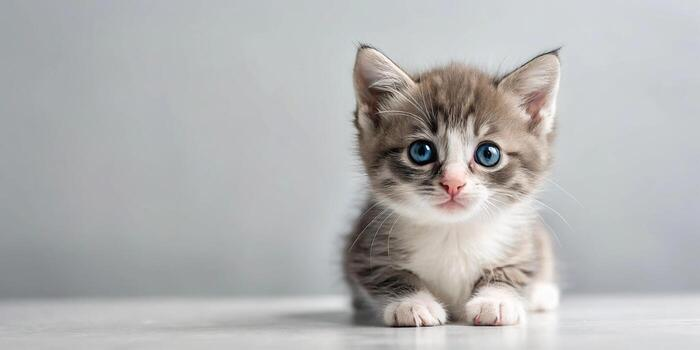

In [59]:
import base64

def analyze_image(path, model):
    with open(path, "rb") as f:
        b64 = base64.b64encode(f.read()).decode()
    prompt = """Analyze this image.

Identify:
1. Main objects
2. Environment
3. Text visible in the image
4. Possible interpretation"""
    return generate(prompt, model=model, images=[b64])

if os.path.exists(IMAGE_PATH):
    out = analyze_image(IMAGE_PATH, VISION_MODEL)
    print(out["response"], f"\n⏱ {out['wall_s']:.1f}s")
    from IPython.display import Image, display
    display(Image(IMAGE_PATH, width=400))
else:
    print(f"⚠️ Put an image named '{IMAGE_PATH}' next to this notebook, then re-run.")

### Questions
- Difference between an LLM and a multimodal model?
- What additional information does the vision model receive?
- Which applications could use local vision AI? *(document analysis, OCR, industrial inspection, education, medical-image preprocessing, surveillance analysis…)*

**✍️ Your answer:**

*An LLM mainly processes text, while a multimodal model can process text, images, and other data types.*
*The vision model receives image data, allowing it to identify objects, environments, and visible text.*
*Local vision AI can be used for document analysis, OCR, industrial inspection, education, medical-image preprocessing, and surveillance analysis.*

## Part 15 — Build a Local AI Web Application
Structure:
```
local-ai-web/
├── app.py
├── templates/index.html
└── static/
```

In [60]:
!pip install -q flask requests
os.makedirs("local-ai-web/templates", exist_ok=True)
os.makedirs("local-ai-web/static", exist_ok=True)

In [61]:
%%writefile local-ai-web/app.py
from flask import Flask, render_template, request
import requests

app = Flask(__name__)

OLLAMA_URL = "http://localhost:11434/api/generate"
MODEL = "qwen3.5:4b"


@app.route("/", methods=["GET", "POST"])
def index():
    answer = ""

    if request.method == "POST":
        question = request.form["question"]
        data = {"model": MODEL, "prompt": question, "stream": False}
        response = requests.post(OLLAMA_URL, json=data)
        answer = response.json()["response"]

    return render_template("index.html", answer=answer)


if __name__ == "__main__":
    app.run(debug=True)

Writing local-ai-web/app.py


In [62]:
%%writefile local-ai-web/templates/index.html
<!DOCTYPE html>
<html>
<head>
    <title>Local AI Assistant</title>
</head>
<body>

<h1>Local AI Assistant</h1>

<form method="POST">
    <textarea name="question" rows="8" cols="70" placeholder="Ask your local AI..."></textarea>
    <br><br>
    <button type="submit">Ask</button>
</form>

{% if answer %}
<h2>Response</h2>
<pre>{{ answer }}</pre>
{% endif %}

</body>
</html>

Writing local-ai-web/templates/index.html


Run it **from a terminal** (not inside the notebook):
```bash
cd local-ai-web
python app.py
```
then open <http://127.0.0.1:5000>. 🎉 You now have a complete local AI web application.

*(📸 Take a screenshot for your report: `screenshots/06_webapp.png`.)*

## Part 16 — Performance Benchmark
We measure: response time, model size, tokens generated, tokens/second, RAM and GPU consumption.

Ollama returns precise counters: `eval_count` (generated tokens), `eval_duration` (ns), `prompt_eval_count`, `load_duration`.

In [63]:
!pip install -q psutil

In [64]:
%%writefile benchmark.py
"""Benchmark local Ollama models on the same prompt."""
import time, requests, psutil, pandas as pd

OLLAMA = "http://localhost:11434"
PROMPT = "Write a 500-word explanation of reinforcement learning."


def unload(model):
    requests.post(f"{OLLAMA}/api/generate", json={"model": model, "keep_alive": 0})
    time.sleep(2)


def loaded_info(model):
    for m in requests.get(f"{OLLAMA}/api/ps").json()["models"]:
        if m["name"].startswith(model.split(":")[0]):
            return m["size"] / 1e9, m.get("size_vram", 0) / 1e9
    return float("nan"), float("nan")


def bench(model, prompt=PROMPT, runs=1):
    rows = []
    for _ in range(runs):
        unload(model)                       # cold start, so the load time is visible
        t0 = time.perf_counter()
        r = requests.post(f"{OLLAMA}/api/generate",
                          json={"model": model, "prompt": prompt, "stream": False,
                                "think": False}, timeout=900).json()
        wall = time.perf_counter() - t0
        total_gb, vram_gb = loaded_info(model)
        rows.append({
            "Model": model,
            "Disk size (GB)": next((m["size"] / 1e9 for m in requests.get(f"{OLLAMA}/api/tags").json()["models"]
                                    if m["name"].startswith(model.split(":")[0])), float("nan")),
            "Loaded size (GB)": total_gb,
            "VRAM (GB)": vram_gb,
            "Load time (s)": r.get("load_duration", 0) / 1e9,
            "Response time (s)": wall,
            "Tokens": r.get("eval_count"),
            "Tokens/s": r["eval_count"] / (r["eval_duration"] / 1e9),
            "System RAM used (%)": psutil.virtual_memory().percent,
        })
    return pd.DataFrame(rows)


if __name__ == "__main__":
    import sys
    print(pd.concat([bench(m) for m in sys.argv[1:]]).round(2).to_string(index=False))

Writing benchmark.py


In [65]:
import benchmark; importlib.reload(benchmark)

bench_df = pd.concat([benchmark.bench(m) for m in (MODEL, MODEL2)], ignore_index=True)
bench_df["Quality /5"] = None   # <- fill in after reading both answers
bench_df.round(2)

,Model,Disk size (GB),Loaded size (GB),VRAM (GB),Load time (s),Response time (s),Tokens,Tokens/s,System RAM used (%),Quality /5
0,qwen3.5:4b,6.55,3.20,0.10,44.45,181.66,803,6.00,86.6,None
1,gemma3:4b,3.35,2.93,0.11,37.75,134.60,801,8.55,84.0,None


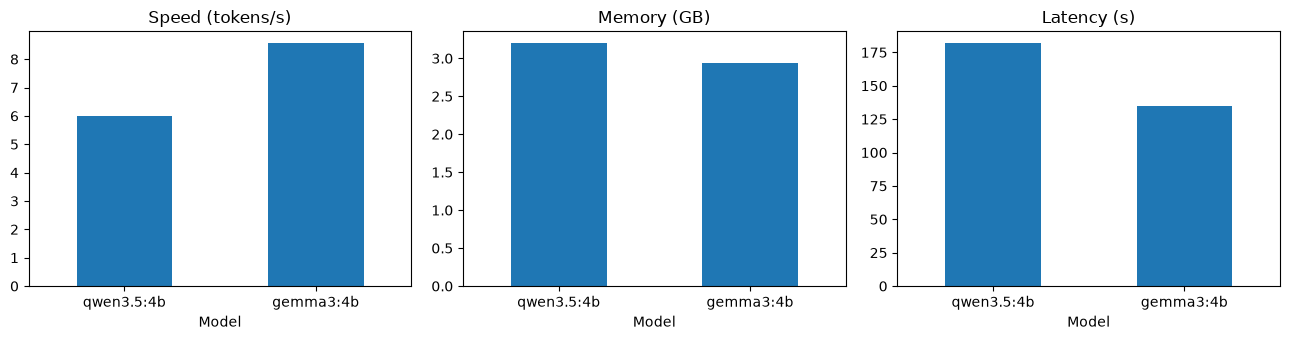

In [66]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
bench_df.plot.bar(x="Model", y="Tokens/s", ax=ax[0], legend=False, title="Speed (tokens/s)", rot=0)
bench_df.plot.bar(x="Model", y="Loaded size (GB)", ax=ax[1], legend=False, title="Memory (GB)", rot=0)
bench_df.plot.bar(x="Model", y="Response time (s)", ax=ax[2], legend=False, title="Latency (s)", rot=0)
plt.tight_layout(); plt.show()

### Discussion — the model-size trade-off
```
Model size ──► Quality
           ──► Memory
           ──► Latency
           ──► Hardware requirements
```
Local model selection should be based on **actual measurements on the target machine**, not just public benchmark rankings.

**✍️ Your discussion:**

*Gemma3:4b performed better on my computer. It was faster (8.55 vs. 6.00 tokens/s), used less RAM (84% vs. 86.6%), and needed less disk space (3.35 GB vs. 6.55 GB). Therefore, Gemma3:4b is a better choice for my 16 GB RAM computer. However, I did not compare the quality of their answers.*

## Part 17 — Final Mini Project: **FSTT Local AI Assistant**

**Functional requirements:** runs entirely locally · uses Ollama + a local LLM · web interface · answers questions about a supplied course · uses local documents as knowledge · maintains conversation history · structured responses for selected questions · displays the answer · records response time.

```
Browser → Flask/Python ─┬─ Conversation history ─┐
                        └─ Documents → Retriever ┴─► Ollama → Local LLM
```

We reuse `rag.py` and create the final deliverable layout:
```
LocalAI_Lab/
├── source/ (app.py, chatbot.py, rag.py, benchmark.py, templates/)
├── documents/
├── screenshots/
├── report.pdf
└── README.md
```

In [67]:
import shutil
base = "LocalAI_Lab"
for d in ("source/templates", "documents", "screenshots"):
    os.makedirs(f"{base}/{d}", exist_ok=True)

# copy shared modules and documents into the deliverable layout
shutil.copy("rag.py", f"{base}/source/rag.py")
shutil.copy("benchmark.py", f"{base}/source/benchmark.py")
for fn in os.listdir("documents"):
    shutil.copy(f"documents/{fn}", f"{base}/documents/{fn}")
print(sorted(os.listdir(base)))

['documents', 'screenshots', 'source']


In [72]:
%%writefile LocalAI_Lab/source/chatbot.py
"""Console chatbot with conversation memory (uses /api/chat)."""
import requests

OLLAMA = "http://localhost:11434"
MODEL = "gemma3:4b"


def main():
    messages = [{"role": "system", "content": "You are a helpful, concise assistant."}]
    print("Local AI Assistant — type 'exit' to stop.")
    while True:
        q = input("\nYou: ")
        if q.lower() == "exit":
            break
        messages.append({"role": "user", "content": q})
        r = requests.post(f"{OLLAMA}/api/chat",
                          json={"model": MODEL, "messages": messages, "stream": False})
        r.raise_for_status()
        reply = r.json()["message"]
        messages.append({"role": "assistant", "content": reply["content"]})
        print("\nAI:", reply["content"])


if __name__ == "__main__":
    main()

Overwriting LocalAI_Lab/source/chatbot.py


In [73]:
%%writefile LocalAI_Lab/source/app.py
"""FSTT Local AI Assistant — Flask + Ollama + local RAG + conversation history."""
import json, os, time
import requests
from flask import Flask, jsonify, render_template, request

import rag

OLLAMA = os.environ.get("OLLAMA_URL", "http://localhost:11434")
MODEL = os.environ.get("MODEL", "gemma3:4b")
DOC_DIR = os.path.join(os.path.dirname(__file__), "..", "documents")
MAX_TURNS = 6                      # remembered user/assistant pairs

app = Flask(__name__)
retriever = rag.Retriever(rag.load_documents(DOC_DIR))
history = []                       # [{"role": ..., "content": ...}]  (single-user demo)

SYSTEM = ("You are the FSTT Local AI Assistant. Answer questions about the course using only the "
          "provided CONTEXT. If the answer is not in the context, say: \"Information not available.\" "
          "Be concise.")

# Structured response schema used for "Analyze ..." / "Quiz ..." style questions
STRUCT_SCHEMA = {
    "type": "object",
    "properties": {
        "topic": {"type": "string"},
        "summary": {"type": "string"},
        "key_points": {"type": "array", "items": {"type": "string"}},
        "difficulty": {"type": "string", "enum": ["easy", "medium", "hard"]},
    },
    "required": ["topic", "summary", "key_points", "difficulty"],
}


def call_ollama(messages, structured=False):
    payload = {"model": MODEL, "messages": messages, "stream": False, "think": False}
    if structured:
        payload["format"] = STRUCT_SCHEMA
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()


@app.route("/")
def index():
    return render_template("index.html", model=MODEL, docs=list(retriever.docs))


@app.route("/ask", methods=["POST"])
def ask():
    body = request.get_json(force=True)
    question = (body.get("question") or "").strip()
    structured = bool(body.get("structured"))
    if not question:
        return jsonify(error="Empty question"), 400

    hits, context = retriever.context(question, k=2)
    user_msg = f"CONTEXT:\n{context or '(none)'}\n\nQUESTION: {question}"
    messages = [{"role": "system", "content": SYSTEM}] + history[-2 * MAX_TURNS:] \
               + [{"role": "user", "content": user_msg}]

    t0 = time.perf_counter()
    try:
        out = call_ollama(messages, structured)
    except requests.RequestException as e:
        return jsonify(error=f"Ollama error: {e}"), 502
    elapsed = time.perf_counter() - t0

    answer = out["message"]["content"]
    # store the plain question (not the long context) to keep history small
    history.append({"role": "user", "content": question})
    history.append({"role": "assistant", "content": answer})

    parsed = None
    if structured:
        try:
            parsed = json.loads(answer)
        except json.JSONDecodeError:
            pass

    tokens = out.get("eval_count")
    tps = tokens / (out["eval_duration"] / 1e9) if tokens and out.get("eval_duration") else None
    return jsonify(answer=answer, structured=parsed,
                   sources=[{"doc": n, "score": round(s, 2)} for n, s in hits],
                   seconds=round(elapsed, 2), tokens=tokens,
                   tokens_per_s=round(tps, 1) if tps else None)


@app.route("/reset", methods=["POST"])
def reset():
    history.clear()
    return jsonify(ok=True)


if __name__ == "__main__":
    # Bind to localhost ONLY (see report question Q15 on security)
    app.run(host="127.0.0.1", port=int(os.environ.get("PORT", 5001)), debug=False)

Overwriting LocalAI_Lab/source/app.py


In [74]:
%%writefile LocalAI_Lab/source/templates/index.html
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<title>FSTT Local AI Assistant</title>
<style>
  body { font-family: system-ui, sans-serif; max-width: 820px; margin: 2rem auto; padding: 0 1rem; color:#222; }
  h1 { margin-bottom: .2rem; } .sub { color:#666; font-size:.9rem; margin-bottom:1rem; }
  #chat { border:1px solid #ddd; border-radius:8px; padding:1rem; height:420px; overflow-y:auto; background:#fafafa; }
  .msg { margin:.6rem 0; padding:.6rem .8rem; border-radius:8px; white-space:pre-wrap; }
  .user { background:#e3f0ff; } .ai { background:#fff; border:1px solid #e5e5e5; }
  .meta { font-size:.75rem; color:#777; margin-top:.3rem; }
  form { display:flex; gap:.5rem; margin-top:1rem; } input[type=text] { flex:1; padding:.6rem; }
  button { padding:.6rem 1rem; cursor:pointer; } label { font-size:.85rem; }
</style>
</head>
<body>
<h1>🎓 FSTT Local AI Assistant</h1>
<div class="sub">Model: <b>{{ model }}</b> · Documents: {{ docs|join(", ") }} · Runs 100% locally</div>
<div id="chat"></div>
<form id="f">
  <input type="text" id="q" placeholder="Ask a question about the course..." autocomplete="off" autofocus>
  <button type="submit">Ask</button>
  <button type="button" id="reset">Reset</button>
</form>
<label><input type="checkbox" id="struct"> Structured response (JSON)</label>

<script>
const chat = document.getElementById("chat");
function add(cls, text, meta) {
  const d = document.createElement("div"); d.className = "msg " + cls; d.textContent = text;
  if (meta) { const m = document.createElement("div"); m.className = "meta"; m.textContent = meta; d.appendChild(m); }
  chat.appendChild(d); chat.scrollTop = chat.scrollHeight; return d;
}
document.getElementById("f").onsubmit = async (e) => {
  e.preventDefault();
  const q = document.getElementById("q"); const question = q.value.trim(); if (!question) return;
  q.value = ""; add("user", question);
  const wait = add("ai", "…thinking…");
  try {
    const r = await fetch("/ask", {method:"POST", headers:{"Content-Type":"application/json"},
      body: JSON.stringify({question, structured: document.getElementById("struct").checked})});
    const j = await r.json(); wait.remove();
    if (j.error) { add("ai", "⚠️ " + j.error); return; }
    const text = j.structured ? JSON.stringify(j.structured, null, 2) : j.answer;
    const src = j.sources.map(s => s.doc).join(", ") || "none";
    add("ai", text, `⏱ ${j.seconds}s · ${j.tokens ?? "?"} tokens · ${j.tokens_per_s ?? "?"} tok/s · sources: ${src}`);
  } catch (err) { wait.remove(); add("ai", "⚠️ " + err); }
};
document.getElementById("reset").onclick = async () => { await fetch("/reset", {method:"POST"}); chat.innerHTML = ""; };
</script>
</body>
</html>

Writing LocalAI_Lab/source/templates/index.html


In [75]:
%%writefile LocalAI_Lab/README.md
# FSTT Local AI Assistant

A fully local assistant: Flask web UI → Ollama → local LLM, with a keyword (TF-IDF) retriever over `documents/`,
conversation history, structured (JSON) answers and response-time display.

## Setup
```bash
ollama pull qwen3.5
pip install flask requests psutil pandas
```

## Run
```bash
cd source
python app.py            # http://127.0.0.1:5001
python chatbot.py        # console chatbot
python benchmark.py qwen3.5 gemma3
```
Environment variables: `MODEL`, `OLLAMA_URL`, `PORT`.

Writing LocalAI_Lab/README.md


**Test the final app from the notebook:** launch it as a background process, send a few questions, then stop it.

In [78]:
import subprocess, sys, time

env = {**os.environ, "MODEL": MODEL, "PORT": "5001"}
server = subprocess.Popen([sys.executable, "app.py"], cwd="LocalAI_Lab/source", env=env,
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
time.sleep(3)

def app_ask(q, structured=False):
    r = requests.post("http://127.0.0.1:5001/ask", json={"question": q, "structured": structured}, timeout=600)
    return r.json()

try:
    for q, s in [("What is reinforcement learning?", False),
                 ("And how is it different from supervised learning?", False),   # tests history
                 ("Summarize deep learning", True),                              # structured
                 ("What is quantum computing?", False)]:                         # not in the docs
        j = app_ask(q, s)
        print(f"Q: {q}\nA: {j.get('structured') or j.get('answer') or j}\n"
              f"   sources={j.get('sources')} · {j.get('seconds')}s · {j.get('tokens_per_s')} tok/s\n")
finally:
    pass  # keep running so you can open http://127.0.0.1:5001 — stop in the next cell

Q: What is reinforcement learning?
A: Reinforcement learning learns through interaction with an environment using rewards and penalties. An agent observes a state, chooses an action, and receives a reward. The goal is to learn a policy that maximizes the cumulative reward. Common algorithms include Q-learning and policy gradients.
   sources=[{'doc': 'course.txt', 'score': 1.08}, {'doc': 'reinforcement_learning.txt', 'score': 1.02}] · 12.67s · 5.7 tok/s

Q: And how is it different from supervised learning?
A: Reinforcement learning learns through interaction with an environment using rewards and penalties, whereas supervised learning uses labelled data to learn a mapping from inputs to outputs (such as classification or regression).
   sources=[{'doc': 'course.txt', 'score': 1.08}, {'doc': 'machine_learning.txt', 'score': 1.06}] · 11.42s · 5.9 tok/s

Q: Summarize deep learning
A: {'difficulty': 'medium', 'key_points': ['Uses artificial neural networks with many layers.', 'Learns repres

In [77]:
server.terminate(); server.wait(timeout=10)
print("Server stopped.")

Server stopped.


> 📸 Open <http://127.0.0.1:5001> in your browser while the server is running and take your screenshots: `01_installation.png`, `02_model.png`, `03_chatbot.png`, `04_python.png`, `05_rag.png`, `06_webapp.png`.

## Part 18 — Questions for the Report
Answer each question in your own words (use your measurements from Parts 6 and 16 for Q13–Q14).

**Q1.** What is Local AI?

*Local AI means running artificial intelligence models directly on a personal computer without depending on cloud servers.*

**Q2.** Difference between a Cloud LLM and a Local LLM?

*A Cloud LLM runs on remote servers and usually requires an internet connection. A Local LLM runs on your own computer and can work offline.*

**Q3.** What role does Ollama play?

*Ollama allows us to download, manage, and run language models locally. It also provides an API to connect these models to Python applications.*

**Q4.** What is model quantization?

*Quantization reduces the numerical precision of model weights to decrease memory usage and improve performance, sometimes with a small loss in accuracy.*

**Q5.** Why does model size affect memory consumption?

*Larger models usually contain more parameters, which require more RAM or GPU memory during execution.*

**Q6.** Why can a smaller model sometimes be preferable?

*Smaller models generally require less memory, run faster, and work better on computers with limited hardware resources.*

**Q7.** Advantages of local inference?

*Local inference improves data privacy, allows offline use, avoids per-request cloud API costs, and provides greater control over the model.*

**Q8.** Disadvantages of local inference?

*Local inference requires sufficient hardware resources. Models can be slower, consume significant RAM, and require installation and maintenance.*

**Q9.** Explain the architecture of your Python application.

*My application uses Flask for the web interface, Python for processing requests, RAG to retrieve information from local documents, and Ollama to generate answers. It also maintains conversation history and measures response time.*

**Q10.** Explain the role of the REST API.

*The REST API allows my Python application to communicate with Ollama using HTTP requests and receive generated responses in JSON format.*

**Q11.** What is RAG?

*RAG (Retrieval-Augmented Generation) retrieves relevant information from documents and provides it to the language model to generate more accurate, context-based answers.*

**Q12.** Difference between an LLM and a multimodal LLM?

*A traditional LLM mainly processes text, while a multimodal LLM can process different types of information, such as text and images. In my experiment, Gemma 3 analyzed an image.*

**Q13.** Compare two local models experimentally.

*Gemma3:4b performed better in this experiment. It generated text faster, responded in less time, and used slightly less memory. However, I did not formally evaluate answer quality.* 
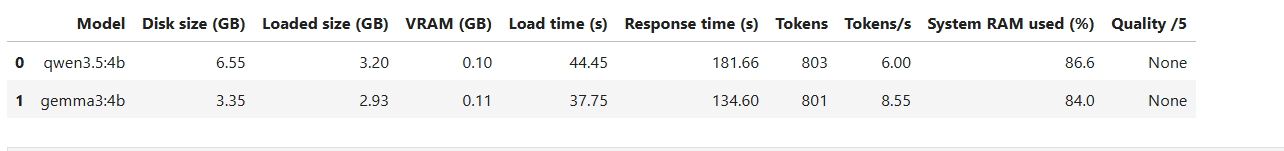 

**Q14.** Which model would you deploy on a computer with limited RAM? Explain.

*I would choose Gemma3:4b because it used less memory (84% versus 86.6%) and generated text faster (8.55 versus 6.00 tokens/second). It is more suitable for my computer with 16 GB RAM.*

**Q15.** What security risks exist when exposing a local LLM server to a network?

*Exposing Ollama to a network can allow unauthorized users to access the model because Ollama does not provide authentication by default. Attackers could consume computing resources, access exposed data, or use malicious documents for prompt injection. To reduce these risks, I would use a firewall, authentication, HTTPS through a reverse proxy, and restrict access to trusted users.*
*(Hint: Ollama has no authentication by default; think about `OLLAMA_HOST=0.0.0.0`, unauthorized use of your compute, model/data exposure, prompt injection through documents, and what a reverse proxy with auth/TLS or a firewall would change.)*

## Part 19 — Deliverables
Final check of the submission folder:
```
LocalAI_Lab/
├── report.pdf
├── source/        app.py · chatbot.py · rag.py · benchmark.py
├── documents/     ai.txt · ml.txt · rl.txt  (+ the other course files)
├── screenshots/   01_installation.png … 06_webapp.png
└── README.md
```

In [ ]:
required = [
    "LocalAI_Lab/report.pdf",
    "LocalAI_Lab/README.md",
    "LocalAI_Lab/source/app.py", "LocalAI_Lab/source/chatbot.py",
    "LocalAI_Lab/source/rag.py", "LocalAI_Lab/source/benchmark.py",
    "LocalAI_Lab/screenshots/01_installation.png", "LocalAI_Lab/screenshots/02_model.png",
    "LocalAI_Lab/screenshots/03_chatbot.png", "LocalAI_Lab/screenshots/04_python.png",
    "LocalAI_Lab/screenshots/05_rag.png", "LocalAI_Lab/screenshots/06_webapp.png",
]
for p in required:
    print("✅" if os.path.exists(p) else "⬜ missing", p)
print("\nDocuments:", sorted(os.listdir("LocalAI_Lab/documents")))